*Mathematical Foundations of Robotics · Chapter 1 — Introduction, Joints and Degrees of Freedom*

# 1.1 Robots, Links and Joints

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kushagrathisside/Robotics-Guide/blob/main/MFoR/01-introduction-and-degrees-of-freedom/1.1-robots-links-and-joints.ipynb)

A robot arm is, at bottom, a chain of rigid bodies connected by joints that allow only a few simple relative motions.
This opening notebook explains why the whole subject can be reduced to mathematics, sketches how the chapters of the
course fit together, and then builds the vocabulary used everywhere else: **links**, **joints**, the six **lower
pairs**, **serial** and **closed** kinematic chains, and the way manipulators are named and classified
(RRR, SCARA, spherical, …). Every definition is checked against real robot models in the MuJoCo simulator.

| | |
|:--|:--|
| **Primary reading** | Craig, *Introduction to Robotics: Mechanics and Control*, 3rd ed., Ch. 1 (Introduction) |
| **Parallel reading** | Lynch & Park, *Modern Robotics*, Ch. 2 (Configuration Space; the table of joint types) · Spong, Hutchinson & Vidyasagar, Ch. 1 · Siciliano et al., Ch. 1 (classification of manipulators) |
| **Lectures** | [Prof. G. C. Nandi — Lecture 1 — Introduction](https://www.youtube.com/watch?v=7_EEBOgdGM8) · [Prof. G. C. Nandi — Lecture 2 — A simple two-link manipulator](https://www.youtube.com/watch?v=4eAlCjFMq2Q) · [Modern Robotics — 2.2 DOF of a robot (Grübler)](https://www.youtube.com/watch?v=zI64DyaRUvQ) |
| **Prerequisites** | none beyond school mechanics and trigonometry; the [Mathematics Primer](../../math-primer/README.md) helps with vectors and angles |
| **Study time** | about 2½ hours, including the exercises |

## Learning objectives

After working through this notebook you should be able to:

1. explain the role of mathematics in robotics and name the six questions — forward kinematics, inverse kinematics, Jacobian, statics, dynamics, trajectory/control — that the chapters of this course answer;
2. define link, joint, base, end-effector, actuator and sensor, and justify the **rigid-body idealisation** of a link;
3. list the six **lower pairs** (revolute, prismatic, helical, cylindrical, spherical, planar), state the freedom $f$ and the number of constraints $c = 6-f$ of each, and distinguish them from higher pairs;
4. tell **serial**, **tree** and **closed** kinematic chains apart, and count the independent loops of a mechanism from its link–joint graph;
5. name a manipulator by its joint sequence, split it into *arm* and *wrist*, and recognise the five classical arm geometries (Cartesian, cylindrical, spherical, SCARA, articulated);
6. reproduce all of the above in MuJoCo on the Dynamixel 2R arm, the UR5e and the humanoid OP3.

## Contents

1. [Why mathematics? The whole course in one picture](#1.-Why-mathematics?-The-whole-course-in-one-picture)
2. [Anatomy of a manipulator](#2.-Anatomy-of-a-manipulator)
3. [Kinematic pairs and the six lower pairs](#3.-Kinematic-pairs-and-the-six-lower-pairs)
4. [Kinematic chains: serial, tree and closed](#4.-Kinematic-chains:-serial,-tree-and-closed)
5. [Naming and classifying manipulators](#5.-Naming-and-classifying-manipulators)
6. [Worked examples](#6.-Worked-examples)
7. [Summary, common mistakes and exercises](#7.-Summary)

In [1]:
# ── Setup ─────────────────────────────────────────────────────────────────────
# Makes the shared `rgkit` package importable, both locally and on Google Colab.
import sys, pathlib, subprocess
if "google.colab" in sys.modules:                                   # Colab
    if not pathlib.Path("Robotics-Guide").exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/kushagrathisside/Robotics-Guide.git"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mujoco", "mediapy"], check=True)
    sys.path.insert(0, "Robotics-Guide")
else:                                                               # local Jupyter
    root = pathlib.Path.cwd().resolve()
    while not (root / "rgkit").is_dir() and root != root.parent:
        root = root.parent
    sys.path.insert(0, str(root))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Math, Markdown
import ipywidgets as widgets

from rgkit import setup_notebook, interact
from rgkit.plotting import (new_axes3d, draw_frame, draw_vector, draw_point, draw_box,
                            draw_frame_2d, draw_vector_2d, matrix_to_latex, AXIS_COLORS)
from rgkit.animation import animate, filmstrip

setup_notebook()
deg = np.deg2rad          # degrees -> radians

from rgkit import mujoco_utils as mju, robots, joint_census as jc, mechanisms as mech
import mujoco

## 1. Why mathematics? The whole course in one picture

A robot manipulator is a machine that moves a **tool** — a gripper, a welding torch, a camera — to places in space
where the tool is needed. The designer's problem is not mechanical strength alone; it is *geometry and motion*.
Suppose the controller of a robot arm is told to put the tool at a given point. Before a single motor turns it must
settle questions that no amount of hardware can answer by itself:

* **Where is the hand now**, given the readings of the joint sensors? (This is **forward kinematics**, Chapter 3.)
* **Which joint angles put the hand where it must go?** (**Inverse kinematics**, Chapter 4 — there may be several
  answers, or none.)
* **How fast does the hand move when the joints move, and where is the arm unable to move in some direction?**
  (The **Jacobian** and **singularities**, Chapter 5.)
* **What torques must the motors apply to hold a load, or to push with a given force?** (**Statics**, Chapter 5.)
* **What torques produce a prescribed acceleration?** (**Dynamics**, Chapter 6.)
* **Along what path, and with what timing, should the joints move so that the motion is smooth?**
  (**Trajectory generation**, Chapter 7; and **control**, the second course, *Robot Motion Control*.)

All six questions are posed in the common language of Chapter 2 — *frames, rotation matrices and homogeneous
transforms* — and all are answered with the same raw material: the numbers that describe the **joints**. That is why
this chapter comes first. Before we can compute with a robot we must say precisely what a robot *is* as a
mathematical object: how many numbers describe its configuration (its **degrees of freedom**), what shape the set of
all configurations has (its **configuration space**), and which positions the hand can reach (its **workspace**).
Chapters 1.1–1.5 answer these questions.

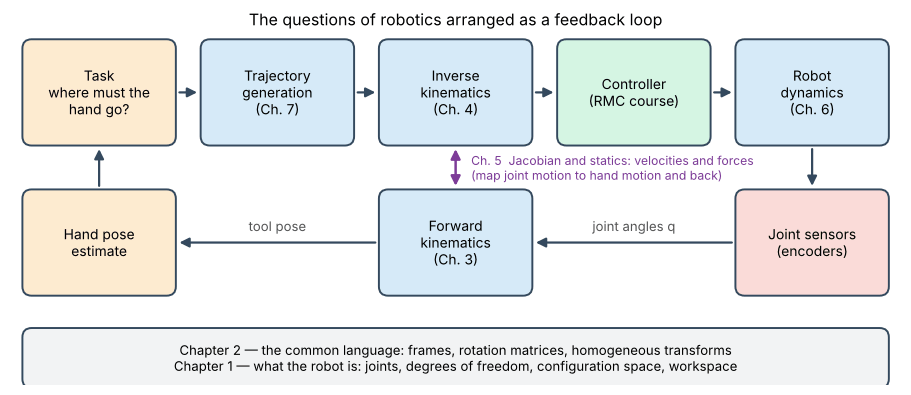

In [2]:
# The course as a feedback loop: boxes are what a robot controller must compute, labels give the chapter.
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(11.5, 4.6))
ax.set_xlim(0, 11.5); ax.set_ylim(0, 4.6); ax.set_axis_off(); ax.grid(False)

def box(x, y, w, h, text, fc, ec="#34495e", fs=10):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.04,rounding_size=0.12", fc=fc, ec=ec, lw=1.4))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs)

def arrow(p, q, color="#34495e", style="-|>", rad=0.0, lw=1.6):
    ax.add_patch(FancyArrowPatch(p, q, arrowstyle=style, mutation_scale=14, lw=lw, color=color,
                                 connectionstyle=f"arc3,rad={rad}"))

cols = [0.2, 2.5, 4.8, 7.1, 9.4]                                   # five columns, each 1.9 wide
top = [("Task\nwhere must the\nhand go?", "#fdebd0"), ("Trajectory\ngeneration\n(Ch. 7)", "#d6eaf8"),
       ("Inverse\nkinematics\n(Ch. 4)", "#d6eaf8"), ("Controller\n(RMC course)", "#d5f5e3"), ("Robot\ndynamics\n(Ch. 6)", "#d6eaf8")]
for x, (t, c) in zip(cols, top):
    box(x, 3.15, 1.9, 1.3, t, c)
for a_, b_ in zip(cols[:-1], cols[1:]):
    arrow((a_ + 1.95, 3.8), (b_ - 0.05, 3.8))
box(9.4, 1.2, 1.9, 1.3, "Joint sensors\n(encoders)", "#fadbd8")
box(4.8, 1.2, 1.9, 1.3, "Forward\nkinematics\n(Ch. 3)", "#d6eaf8")
box(0.2, 1.2, 1.9, 1.3, "Hand pose\nestimate", "#fdebd0")
arrow((10.35, 3.1), (10.35, 2.55))                                  # robot -> sensors
arrow((9.35, 1.85), (6.75, 1.85)); ax.text(8.05, 2.0, "joint angles q", ha="center", fontsize=9.5, color="#555")
arrow((4.75, 1.85), (2.15, 1.85)); ax.text(3.45, 2.0, "tool pose", ha="center", fontsize=9.5, color="#555")
arrow((1.15, 2.55), (1.15, 3.1))                                    # pose -> task (feedback)
arrow((5.75, 3.1), (5.75, 2.55), style="<|-|>", color="#7d3c98", lw=1.8)
ax.text(5.95, 2.82, "Ch. 5  Jacobian and statics: velocities and forces\n(map joint motion to hand motion and back)", fontsize=8.8, color="#7d3c98", va="center")
box(0.2, 0.0, 11.1, 0.7, "Chapter 2 — the common language: frames, rotation matrices, homogeneous transforms\n"
    "Chapter 1 — what the robot is: joints, degrees of freedom, configuration space, workspace", "#f2f3f4", fs=9.5)
ax.set_title("The questions of robotics arranged as a feedback loop", fontsize=11.5, pad=4)
plt.show()

The diagram is a map, not a prescription: real controllers differ in detail. What matters is that **every box is a
piece of mathematics about the same object** — a chain of rigid bodies whose configuration is described by joint
variables. The Dynamixel 2R arm shown next is the smallest object on which all the boxes can already be
practised, and we shall return to it in every chapter.

### A first example: the planar two-link arm

The Dynamixel 2R from [MuJoCo Menagerie](https://github.com/google-deepmind/mujoco_menagerie) moves in a vertical
plane. Two links of length $L_1$ and $L_2$ are joined by revolute joints with angles $\theta_1$ (at the shoulder) and
$\theta_2$ (at the elbow, measured *relative* to the first link). If we measure angles counter-clockwise from the
$X$ axis of a frame attached to the shoulder, the hand position is, by elementary trigonometry,

$$
X = L_1\cos\theta_1 + L_2\cos(\theta_1+\theta_2),\qquad
Y = L_1\sin\theta_1 + L_2\sin(\theta_1+\theta_2). \tag{1.1}
$$

This is the **forward kinematics** of the 2R arm (Chapter 3 derives it systematically, and Prof. Nandi's Lecture 2
treats exactly this example). Rather than trust the formula, we measure the link lengths *from the simulator's
model* and compare (1.1) with the hand position MuJoCo computes for random joint angles. A small bookkeeping detail:
the model's zero configuration hangs straight **down**, so the textbook plane $(X, Y)$ corresponds to the world
coordinates $(z_0 - z,\ x)$, where $z_0$ is the height of the shoulder.

In [3]:
m2, d2 = robots.load_robot("2r", scene="bare")
print(robots.describe("2r"))
d2.qpos[:] = 0; mujoco.mj_forward(m2, d2)
z0 = d2.xanchor[0][2]                                                   # shoulder height in the world
L1 = np.hypot(*(d2.xanchor[1] - d2.xanchor[0])[[0, 2]])                 # link lengths measured in the plane of motion (x, z)
L2 = np.hypot(*(d2.site("end").xpos - d2.xanchor[1])[[0, 2]])
print(f"measured link lengths: L1 = {L1:.4f} m, L2 = {L2:.4f} m;   joint limits: "
      f"theta1 in ±{np.degrees(m2.jnt_range[0,1]):.0f}°, theta2 in ±{np.degrees(m2.jnt_range[1,1]):.0f}°")

def fk_2r(q):                                      # equation (1.1)
    t1, t12 = q[0], q[0] + q[1]
    return np.array([L1 * np.cos(t1) + L2 * np.cos(t12), L1 * np.sin(t1) + L2 * np.sin(t12)])

def hand_from_mujoco(q):                           # MuJoCo's tool point, expressed in the textbook plane (X down, Y = world x)
    d2.qpos[:] = q; mujoco.mj_forward(m2, d2)
    p = d2.site("end").xpos
    return np.array([z0 - p[2], p[0]])

rng = np.random.default_rng(1)
lo, hi = m2.jnt_range[:, 0], m2.jnt_range[:, 1]
Q = rng.uniform(lo, hi, size=(200, 2))
err = max(np.linalg.norm(fk_2r(q) - hand_from_mujoco(q)) for q in Q)
print(f"largest |formula - MuJoCo| over 200 random configurations: {err:.2e} m")
assert err < 1e-12

Dynamixel 2R arm — model from [MuJoCo Menagerie](https://github.com/google-deepmind/mujoco_menagerie/tree/98a70c56/dynamixel_2r) (Marc Duclusaud & Grégoire Passault; licence: MIT)
measured link lengths: L1 = 0.1800 m, L2 = 0.1800 m;   joint limits: theta1 in ±110°, theta2 in ±150°
largest |formula - MuJoCo| over 200 random configurations: 3.16e-16 m


The agreement to rounding error is our first **cross-check**: a formula derived on paper and an independent
simulator describe the same machine. The explorer below lets you move the two joints and watch the hand; the
shaded region marks the joint limits' effect later in Notebook 1.5.

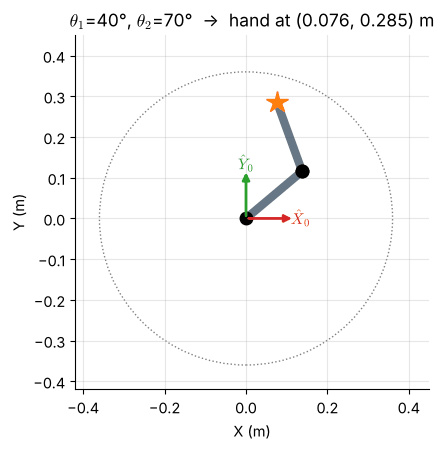

In [4]:
def draw_2r(ax, q, trail=None, color="#34495e"):
    p1 = L1 * np.array([np.cos(q[0]), np.sin(q[0])])
    p2 = p1 + L2 * np.array([np.cos(q[0] + q[1]), np.sin(q[0] + q[1])])
    ax.plot([0, p1[0], p2[0]], [0, p1[1], p2[1]], "-", color=color, lw=6, solid_capstyle="round", alpha=0.75)
    ax.plot([0, p1[0]], [0, p1[1]], "o", color="k", ms=9)
    ax.plot(*p1, "o", color="k", ms=9)
    ax.plot(*p2, "*", color="#ff7f0e", ms=16, zorder=5)
    return p2

def explore(theta1=40.0, theta2=70.0):
    q = np.radians([theta1, theta2])
    fig, ax = plt.subplots(figsize=(5.4, 4.6))
    tip = draw_2r(ax, q)
    draw_frame_2d(ax, 0, name="0", length=0.12)
    ax.add_patch(plt.Circle((0, 0), L1 + L2, fill=False, ls=":", color="grey"))
    ax.set_xlim(-0.42, 0.45); ax.set_ylim(-0.42, 0.45); ax.set_aspect("equal")
    ax.set_xlabel("X (m)"); ax.set_ylabel("Y (m)")
    ax.set_title(rf"$\theta_1$={theta1:.0f}°, $\theta_2$={theta2:.0f}°  →  hand at ({tip[0]:.3f}, {tip[1]:.3f}) m")
    plt.show()
    assert np.allclose(tip, fk_2r(q)) and np.allclose(tip, hand_from_mujoco(q))

interact(explore, theta1=widgets.FloatSlider(40, min=-110, max=110, step=1, description="θ1 (°)"),
         theta2=widgets.FloatSlider(70, min=-150, max=150, step=1, description="θ2 (°)"));

### Two ways to move the hand from $A$ to $B$

The animation previews Chapters 4 and 7. The *same* arm must carry its hand from $A$ to $B$. In the left panel the
joints move at constant speed — a straight line in **joint space**. In the right panel the hand follows a straight
line in **Cartesian space**, which requires solving the inverse-kinematics problem at every instant. Even though both
motions start and end at the same configurations, the hand's path is curved in the first case, and the joints move
non-uniformly in the second. Nothing about the hardware differs; only the mathematics of the *space in which the
motion is planned*. The inverse-kinematics formula used here (law of cosines) is derived in Chapter 4; we check it
against the forward kinematics.

IK check  FK(IK(A)) == A: True   FK(IK(B)) == B: True
q_A = [-47.   57.1] deg,  q_B = [48.2 64.7] deg


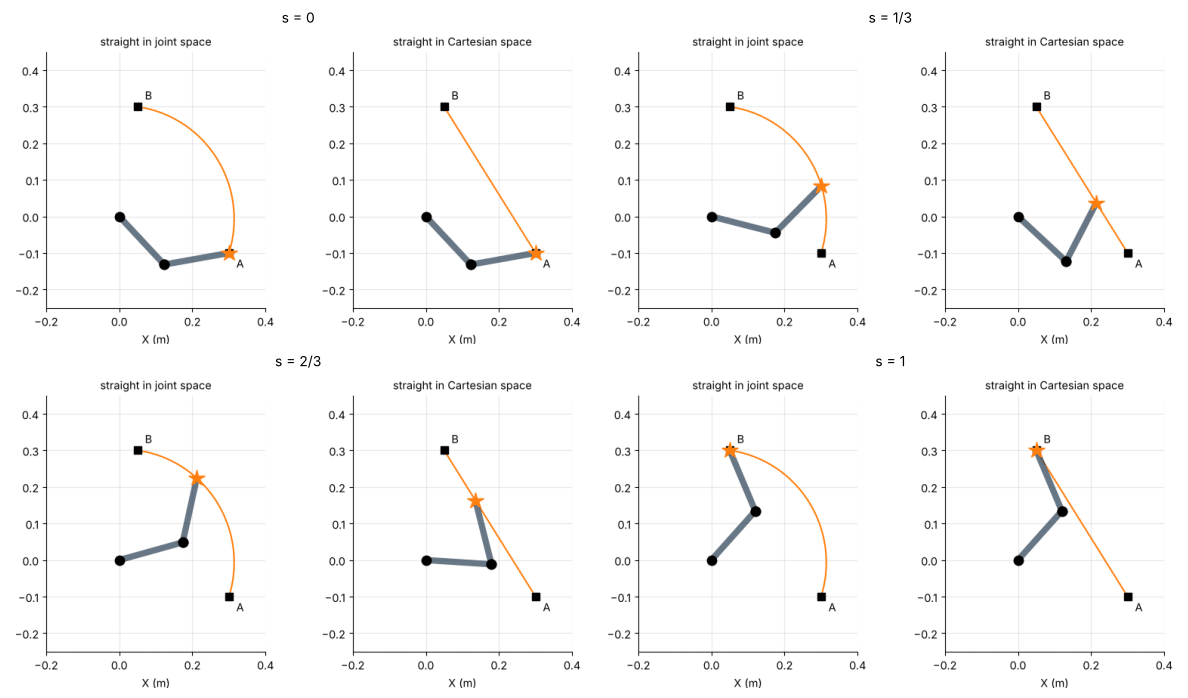

In [5]:
def ik_2r(p, elbow=+1):
    """Closed-form inverse kinematics of the planar 2R (derived in Chapter 4): both elbow branches are possible."""
    x, y = p
    c2 = (x * x + y * y - L1 ** 2 - L2 ** 2) / (2 * L1 * L2)
    q2 = elbow * np.arccos(np.clip(c2, -1, 1))
    q1 = np.arctan2(y, x) - np.arctan2(L2 * np.sin(q2), L1 + L2 * np.cos(q2))
    return np.array([q1, q2])

A, B = np.array([0.30, -0.10]), np.array([0.05, 0.30])
qA, qB = ik_2r(A), ik_2r(B)
print("IK check  FK(IK(A)) == A:", np.allclose(fk_2r(qA), A), "  FK(IK(B)) == B:", np.allclose(fk_2r(qB), B))
print(f"q_A = {np.degrees(qA).round(1)} deg,  q_B = {np.degrees(qB).round(1)} deg")

fig, axs = plt.subplots(1, 2, figsize=(9.6, 4.4))
def update(s):
    q_joint = (1 - s) * qA + s * qB                       # straight line in joint space
    q_cart = ik_2r((1 - s) * A + s * B)                   # straight line in Cartesian space
    for ax, q, ttl, pathf in [(axs[0], q_joint, "straight in joint space", lambda u: fk_2r((1 - u) * qA + u * qB)),
                              (axs[1], q_cart, "straight in Cartesian space", lambda u: (1 - u) * A + u * B)]:
        ax.cla()
        us = np.linspace(0, 1, 60)
        path = np.array([pathf(u) for u in us])
        ax.plot(path[:, 0], path[:, 1], "-", color="#ff7f0e", lw=1.5)
        draw_2r(ax, q)
        ax.plot(*A, "ks", ms=7); ax.plot(*B, "ks", ms=7); ax.text(A[0] + 0.02, A[1] - 0.04, "A"); ax.text(B[0] + 0.02, B[1] + 0.02, "B")
        ax.set_xlim(-0.2, 0.4); ax.set_ylim(-0.25, 0.45); ax.set_aspect("equal"); ax.set_title(ttl, fontsize=10.5)
        ax.set_xlabel("X (m)")
axs[0].set_ylabel("Y (m)")
animate(fig, update, np.linspace(0, 1, 36), interval=80, gif="assets/1.1-two-paths-2r.gif",
        keyframe_titles=["s = 0", "s = 1/3", "s = 2/3", "s = 1"])

## 2. Anatomy of a manipulator

A **robot manipulator** (or *robot arm*) is a set of rigid bodies, the **links**, connected by **joints**. One link,
the **base**, is attached to the ground or to a mobile platform and is *link 0*; the last link carries the
**end-effector** (gripper, tool or sensor), whose position and orientation are what the robot ultimately controls. The
reference point at the end of the last link — the *tool flange* or *tool centre point* — is the place where most
kinematic formulae are evaluated. Each joint is driven by an **actuator** (usually an electric motor with a gear
reducer, called the *transmission*) and monitored by a **sensor** (an encoder or resolver that measures the joint
variable). Together these elements form the chain
$$\text{base (link 0)} \;-\; \text{joint 1} \;-\; \text{link 1} \;-\; \cdots \;-\; \text{joint } n \;-\; \text{link } n \;-\; \text{end-effector}.$$

| Element | Role | Mathematical model |
|:--|:--|:--|
| **Link** | a body whose points keep their mutual distances | one coordinate frame $\{i\}$ per link |
| **Joint** | allows one simple relative motion of two adjacent links | one or more *joint variables* $q_i$ |
| **Base** | link 0, fixed in the workcell | the reference frame $\{0\}$ |
| **End-effector** | the tool; its pose is the *task* | a tool frame $\{T\}$ at the flange |
| **Actuator + transmission** | produces joint motion | a map from motor variables to joint variables |
| **Sensor** | measures joint variables | $q_i$ read by the controller |

The figure labels these elements on a real robot, the Universal Robots UR5e, using MuJoCo's own model: the joint
anchors and the tool flange are read from the simulator and projected onto the image.

Universal Robots UR5e — model from [MuJoCo Menagerie](https://github.com/google-deepmind/mujoco_menagerie/tree/98a70c56/universal_robots_ur5e) (Universal Robots; licence: BSD-3-Clause)


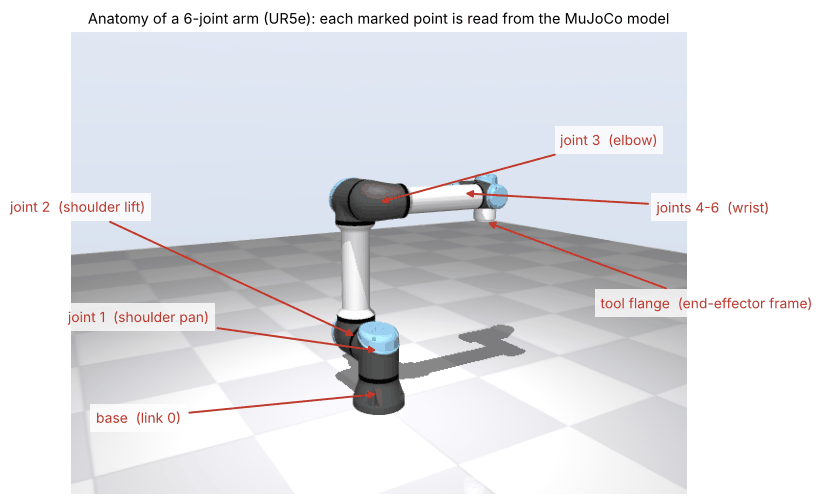

In [6]:
mu, du = robots.load_robot("ur5e", scene="light")                 # starts in the manufacturer's 'home' keyframe
print(robots.describe("ur5e"))
cam = dict(azimuth=150, elevation=-12, distance=1.55, lookat=(0, 0, 0.42))
img = mju.render(mu, du, camera=cam, width=640, height=480)

anchors = {mujoco.mj_id2name(mu, mujoco.mjtObj.mjOBJ_JOINT, j): du.xanchor[j].copy() for j in range(mu.njnt)}
pts = {"base  (link 0)": du.xpos[mujoco.mj_name2id(mu, mujoco.mjtObj.mjOBJ_BODY, "base")] + [0, 0, 0.03],
       "joint 1  (shoulder pan)": anchors["shoulder_pan_joint"],
       "joint 2  (shoulder lift)": anchors["shoulder_lift_joint"],
       "joint 3  (elbow)": anchors["elbow_joint"],
       "joints 4-6  (wrist)": anchors["wrist_2_joint"],
       "tool flange  (end-effector frame)": du.site("attachment_site").xpos.copy()}
uv = jc.project_points(mu, cam, list(pts.values()), 640, 480)

fig, ax = plt.subplots(figsize=(8.4, 6.0)); ax.imshow(img); ax.set_axis_off(); ax.grid(False)
offsets = [(-250, 30), (-250, -30), (-290, -130), (240, -60), (260, 20), (230, 90)]
for (name, _), (u, v), (dx, dy) in zip(pts.items(), uv, offsets):
    ax.annotate(name, xy=(u, v), xytext=(u + dx, v + dy), fontsize=10, ha="center",
                arrowprops=dict(arrowstyle="-|>", color="#c0392b", lw=1.4), color="#c0392b", bbox=dict(fc="white", ec="none", alpha=0.8))
ax.set_title("Anatomy of a 6-joint arm (UR5e): each marked point is read from the MuJoCo model", fontsize=10.5)
plt.show()

### The rigid-body idealisation

Real links bend, vibrate and expand with temperature. Kinematics ignores all of that and treats every link as a
**rigid body**: a set of points whose mutual distances never change. The consequence is a great economy. If a
coordinate frame $\{i\}$ is attached to a rigid link, the *pose of that one frame* fixes the position of **every
point of the link**, so a robot with $n$ links is described by $n$ frames rather than by millions of points. The cell
below tests the idealisation on the UR5e model. Two points are fixed in the forearm's frame; we move the robot to
200 random configurations and compute their world distance. It is constant to rounding error, whereas the
distance between a forearm point and an upper-arm point (different links) changes by tens of centimetres.

In [7]:
rng = np.random.default_rng(0)
bid = lambda n: mujoco.mj_name2id(mu, mujoco.mjtObj.mjOBJ_BODY, n)
p_fore = [np.array([0.0, 0.05, 0.10]), np.array([0.02, -0.04, 0.35])]       # two points fixed in the forearm frame (m)
p_upper = np.array([0.0, 0.03, 0.20])                                       # one point fixed in the upper-arm frame
same, different = [], []
for _ in range(200):
    q = np.array([rng.uniform(lo, hi) if mu.jnt_limited[j] else rng.uniform(-np.pi, np.pi)
                  for j, (lo, hi) in enumerate(mu.jnt_range)])
    du.qpos[:] = q; mujoco.mj_forward(mu, du)
    world = lambda body, p: du.xpos[bid(body)] + du.xmat[bid(body)].reshape(3, 3) @ p
    a, b = world("forearm_link", p_fore[0]), world("forearm_link", p_fore[1])
    c = world("upper_arm_link", p_upper)
    same.append(np.linalg.norm(a - b)); different.append(np.linalg.norm(a - c))
print(f"two points on the SAME link:       distance {min(same):.6f} … {max(same):.6f} m   (spread {np.ptp(same):.1e})")
print(f"points on DIFFERENT links:          distance {min(different):.3f} … {max(different):.3f} m  (spread {np.ptp(different):.3f})")
assert np.ptp(same) < 1e-12 and np.ptp(different) > 0.1

two points on the SAME link:       distance 0.266458 … 0.266458 m   (spread 3.3e-16)
points on DIFFERENT links:          distance 0.167 … 0.343 m  (spread 0.176)


## 3. Kinematic pairs and the six lower pairs

Two bodies in contact that can still move relative to each other form a **kinematic pair**, and a joint is a
physical realisation of one. Pairs are classified by **how the two bodies touch**.

* In a **lower pair** the bodies touch over a *surface* (or surfaces) throughout the motion — a pin in a hole, a
  slider in a groove. Surface contact spreads the load, wears slowly and is easy to lubricate and seal; for that
  reason nearly every robot joint is a lower pair.
* In a **higher pair** the contact is along a *line or at a point* — gear teeth, a cam against its follower, a ball
  rolling on a plane. Higher pairs transmit motion in more elaborate ways but concentrate stress.

The classical analysis of the kinematic pairs (Reuleaux) shows that there are exactly **six lower pairs**. Their
defining property is the number of independent relative motions they allow, the **freedom** $f$; two free bodies in
space have 6 relative freedoms, so the pair imposes **$c = 6 - f$ constraints**. The table lists them together with
the standard symbol used to name robots.

| Pair | Symbol | Relative motion allowed | $f$ | $c=6-f$ | Everyday example |
|:--|:--|:--|:-:|:-:|:--|
| Revolute (hinge) | **R** | rotation about one fixed axis | 1 | 5 | door hinge, robot elbow |
| Prismatic (slider) | **P** | translation along one fixed line | 1 | 5 | drawer, hydraulic cylinder |
| Helical (screw) | **H** | rotation coupled to translation along the axis (pitch $h$) | 1 | 5 | bolt in a nut, lead screw |
| Cylindrical | **C** | independent rotation about and translation along one axis | 2 | 4 | shaft that slides in a bearing |
| Spherical (ball) | **S** | any rotation about a fixed point | 3 | 3 | hip joint, ball-and-socket |
| Planar | **E** | two translations in a plane and a rotation about its normal | 3 | 3 | block sliding on a table |

Two remarks. First, **R and P account for almost every joint of a real robot**, because each needs only one actuator
and one sensor; a multi-freedom joint is usually built from them (a cylindrical joint is an R and a P on one axis, a
spherical joint is three R joints whose axes meet at a point — the *spherical wrist* of Section 5). Second, the
**universal (Hooke) joint** U, two perpendicular intersecting revolute axes, has $f=2$ but is *not* a lower pair; it is
a *composite* of two revolute pairs. Lynch & Park list it in their table of joints for this reason.

The figure shows the six pairs as MuJoCo models. The red lines are the joint axes. The helical pair is not a
primitive joint type in MuJoCo; we build it from a slide and a hinge on one axis, coupled by an *equality constraint*
$z = p\,\varphi$ (the pitch relation), which already shows how a simulator counts freedom.

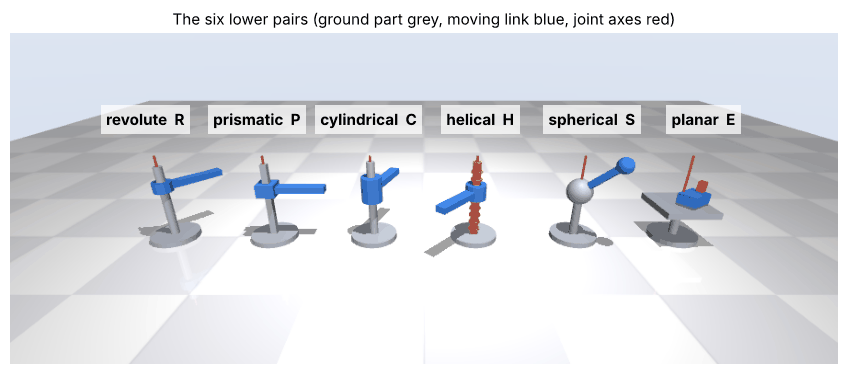

In [8]:
G, B, O, RED = "0.62 0.64 0.68 1", "0.20 0.45 0.80 1", "0.95 0.55 0.15 1", "0.85 0.2 0.2 1"
NC = 'contype="0" conaffinity="0"'
ARM_GEOM = f'<geom type="box" size="0.11 0.02 0.012" pos="0.11 0 0" rgba="{B}" {NC}/>'
PITCH = 0.02                                       # helical pair: axial advance per radian (m/rad)

def pair_xml(kind, x0):
    """MJCF of one lower pair at x = x0: a grey ground part and a coloured moving link."""
    s = f'<geom type="cylinder" size="0.09 0.01" pos="{x0} 0 0.01" rgba="{G}" {NC}/>'
    if kind == "R":
        s += f'<geom type="cylinder" size="0.016 0.14" pos="{x0} 0 0.16" rgba="{G}" {NC}/>'
        s += f'<body name="R" pos="{x0} 0 0.22"><joint name="R1" type="hinge" axis="0 0 1"/><geom type="cylinder" size="0.035 0.02" rgba="{B}" {NC}/>{ARM_GEOM}</body>'
    if kind == "P":
        s += f'<geom type="box" size="0.012 0.012 0.15" pos="{x0} 0 0.16" rgba="{G}" {NC}/>'
        s += f'<body name="P" pos="{x0} 0 0.12"><joint name="P1" type="slide" axis="0 0 1" range="0 0.2"/><geom type="box" size="0.035 0.035 0.025" rgba="{B}" {NC}/>{ARM_GEOM}</body>'
    if kind == "C":
        s += f'<geom type="cylinder" size="0.016 0.15" pos="{x0} 0 0.17" rgba="{G}" {NC}/>'
        s += f'<body name="C" pos="{x0} 0 0.14"><joint name="C1" type="slide" axis="0 0 1" range="0 0.2"/><joint name="C2" type="hinge" axis="0 0 1"/><geom type="cylinder" size="0.04 0.05" rgba="{B}" {NC}/>{ARM_GEOM}</body>'
    if kind == "H":
        s += f'<geom type="cylinder" size="0.016 0.15" pos="{x0} 0 0.17" rgba="{O}" {NC}/>'
        s += "".join(f'<geom type="cylinder" size="0.022 0.003" pos="{x0} 0 {0.04 + 0.03 * k}" rgba="{O}" {NC}/>' for k in range(9))
        s += f'<body name="H" pos="{x0} 0 0.12"><joint name="H1" type="slide" axis="0 0 1" range="0 0.2"/><joint name="H2" type="hinge" axis="0 0 1"/><geom type="cylinder" size="0.04 0.03" rgba="{B}" {NC}/>{ARM_GEOM}</body>'
    if kind == "S":
        s += f'<geom type="cylinder" size="0.016 0.09" pos="{x0} 0 0.10" rgba="{G}" {NC}/><geom type="sphere" size="0.05" pos="{x0} 0 0.20" rgba="{G}" {NC}/>'
        s += f'<body name="S" pos="{x0} 0 0.20"><joint name="S1" type="ball"/><geom type="capsule" fromto="0 0 0 0 0 0.20" size="0.014" rgba="{B}" {NC}/><geom type="sphere" size="0.03" pos="0 0 0.20" rgba="{B}" {NC}/></body>'
    if kind == "E":
        s += f'<geom type="cylinder" size="0.016 0.065" pos="{x0} 0 0.075" rgba="{G}" {NC}/><geom type="box" size="0.10 0.10 0.012" pos="{x0} 0 0.14" rgba="{G}" {NC}/>'
        s += f'<body name="E" pos="{x0} 0 0.18"><joint name="E1" type="slide" axis="1 0 0" range="-0.05 0.05"/><joint name="E2" type="slide" axis="0 1 0" range="-0.05 0.05"/><joint name="E3" type="hinge" axis="0 0 1"/><geom type="box" size="0.05 0.035 0.02" rgba="{B}" {NC}/><geom type="box" size="0.012 0.012 0.03" pos="0.04 0 0.03" rgba="{RED}" {NC}/></body>'
    if kind in "RPCH":
        s += f'<geom type="capsule" fromto="{x0} 0 0.02 {x0} 0 0.34" size="0.004" rgba="{RED}" {NC}/>'
    else:
        s += f'<geom type="capsule" fromto="{x0} 0 0.19 {x0} 0 0.34" size="0.004" rgba="{RED}" {NC}/>'
    return s

EQ_H = f'<equality><joint joint1="H1" joint2="H2" polycoef="0 {PITCH} 0 0 0"/></equality>'      # slide = PITCH * hinge
kinds = ["R", "P", "C", "H", "S", "E"]
xs = np.linspace(-1.0, 1.0, 6)

# --- the picture: all six pairs in one scene, each posed away from its zero configuration
scene = (f'<mujoco><option jacobian="dense"/>{mju.scene_assets(1000, 600)}<worldbody>{mju.floor(0, 3)}'
         + "".join(pair_xml(k, x) for k, x in zip(kinds, xs)) + f'</worldbody>{EQ_H}</mujoco>')
ms, ds = mju.load(scene)
def setq(name, vals):
    a = ms.joint(name).qposadr[0]; ds.qpos[a:a + len(vals)] = vals
setq("R1", [np.radians(50)]); setq("P1", [0.09]); setq("C1", [0.07]); setq("C2", [np.radians(70)])
setq("H2", [4.0]); setq("H1", [PITCH * 4.0]); setq("S1", [np.cos(0.4), 0.707 * np.sin(0.4), 0.707 * np.sin(0.4), 0])
setq("E1", [0.03]); setq("E2", [-0.02]); setq("E3", [np.radians(30)])
mujoco.mj_forward(ms, ds)
cam = dict(azimuth=90, elevation=-24, distance=1.55, lookat=(0, 0, 0.17))
img = mju.render(ms, ds, camera=cam, width=900, height=360)
fig, ax = plt.subplots(figsize=(11, 4.3)); ax.imshow(img); ax.set_axis_off(); ax.grid(False)
names = ["revolute  R", "prismatic  P", "cylindrical  C", "helical  H", "spherical  S", "planar  E"]
for nm, x in zip(names, xs):
    u, v = jc.project_points(ms, cam, [[x, 0, 0.46]], 900, 360)[0]
    ax.text(u, v, nm, ha="center", fontsize=11, weight="bold", bbox=dict(fc="white", ec="none", alpha=0.75))
ax.set_title("The six lower pairs (ground part grey, moving link blue, joint axes red)", fontsize=11)
plt.show()

### Measuring the freedom $f$ of each pair

How can a program decide how many freedoms a pair has? MuJoCo stores a configuration as the vector `qpos` and a
velocity as `qvel`; the number of velocity coordinates, `nv`, counts the freedoms of the *joints as declared*, and
every **equality constraint** removes as many freedoms as the rank of its Jacobian. The helper
`joint_census.model_mobility` returns $n_v - \operatorname{rank}(J_{\mathrm{eq}})$. Applying it to each pair in
isolation reproduces the column $f$ of the table above (and, with $c = 6 - f$, the constraint count).

In [9]:
rows = []
for kind in kinds:
    xml = f'<mujoco><option jacobian="dense"/><worldbody>{pair_xml(kind, 0.0)}</worldbody>{EQ_H if kind == "H" else ""}</mujoco>'
    m, d = mju.load(xml)
    f = jc.model_mobility(m, d)
    rows.append((kind, m.nv, jc.equality_rank(m, d), f, 6 - f))
    assert f == {k: v[1] for k, v in zip("RPHCSE", mech.LOWER_PAIRS.values())}[kind]
table = "| pair | joints declared (nv) | rank of equality constraints | measured f | c = 6 - f |\n|:-:|:-:|:-:|:-:|:-:|\n"
table += "\n".join(f"| {k} | {nv} | {r} | **{f}** | {c} |" for k, nv, r, f, c in rows)
display(Markdown(table))
print("\nThe helical pair is two declared joints (slide + hinge) tied by one equality constraint, hence f = 2 - 1 = 1.")

| pair | joints declared (nv) | rank of equality constraints | measured f | c = 6 - f |
|:-:|:-:|:-:|:-:|:-:|
| R | 1 | 0 | **1** | 5 |
| P | 1 | 0 | **1** | 5 |
| C | 2 | 0 | **2** | 4 |
| H | 2 | 1 | **1** | 5 |
| S | 3 | 0 | **3** | 3 |
| E | 3 | 0 | **3** | 3 |


The helical pair is two declared joints (slide + hinge) tied by one equality constraint, hence f = 2 - 1 = 1.


## 4. Kinematic chains: serial, tree and closed

A mechanism is described by **which links are joined by which joints**. Draw one **vertex** for every link (the
ground included) and one **edge** for every joint. The resulting *link–joint graph* classifies the mechanism.

* **Serial (open) chain** — the graph is a path: link 0 – 1 – 2 – ⋯ – $n$. Almost every industrial arm (PUMA, UR,
  KUKA, ABB) is serial. Each joint is *independent*: any joint values are allowed and the hand pose follows by
  multiplying transforms.
* **Tree** — the graph branches but has no cycle: a humanoid has a torso with two arms, two legs and a head. A tree is
  a collection of serial chains sharing links.
* **Closed (parallel) chain** — the graph contains at least one **loop**. The four-bar linkage, the slider-crank of an
  engine and the Stewart platform are closed chains. The joint values can no longer be chosen independently: they must
  satisfy **loop-closure equations**, and those constraints are what reduce the freedom (Notebook 1.3).

The number of *independent* loops follows from graph theory. A connected graph with $N$ vertices (links) and $J$ edges
(joints) is a tree exactly when $J = N - 1$; every additional edge creates one new independent cycle, so

$$
L = J - N + 1 \qquad (\text{connected mechanism}). \tag{1.2}
$$

We compute (1.2) for four mechanisms from explicit edge lists, and for the humanoid OP3 directly from its MuJoCo
model.

In [10]:
def loops(n_links, edges):
    """Independent loops L = J - N + C (C = number of connected components), by union-find."""
    parent = list(range(n_links))
    def find(i):
        while parent[i] != i: parent[i] = parent[parent[i]]; i = parent[i]
        return i
    for a, b in edges: parent[find(a)] = find(b)
    return len(edges) - n_links + len({find(i) for i in range(n_links)})

serial6 = [(i, i + 1) for i in range(6)]                                    # ground + 6 links
fourbar = [(0, 1), (1, 2), (2, 3), (3, 0)]
# Stewart platform: base 0, platform 1, and for each of 6 legs a lower part and an upper part
stewart = []
for k in range(6):
    lo, up = 2 + 2 * k, 3 + 2 * k
    stewart += [(0, lo), (lo, up), (up, 1)]                                  # universal, prismatic, spherical joints
mop3, dop3 = robots.load_robot("op3", scene="bare")
tree_op3 = jc.kinematic_tree(mop3)
op3_edges = [(i, int(mop3.body_parentid[i])) for i in range(1, mop3.nbody)]
cases = {"serial 6R arm": (7, serial6), "planar four-bar": (4, fourbar), "Stewart platform": (14, stewart),
         "humanoid OP3 (MuJoCo tree)": (mop3.nbody, op3_edges)}
for name, (N, E) in cases.items():
    print(f"{name:26s} N = {N:2d} links, J = {len(E):2d} joints  ->  L = J - N + 1 = {loops(N, E)} independent loop(s)")

serial 6R arm              N =  7 links, J =  6 joints  ->  L = J - N + 1 = 0 independent loop(s)
planar four-bar            N =  4 links, J =  4 joints  ->  L = J - N + 1 = 1 independent loop(s)
Stewart platform           N = 14 links, J = 18 joints  ->  L = J - N + 1 = 5 independent loop(s)
humanoid OP3 (MuJoCo tree) N = 22 links, J = 21 joints  ->  L = J - N + 1 = 0 independent loop(s)


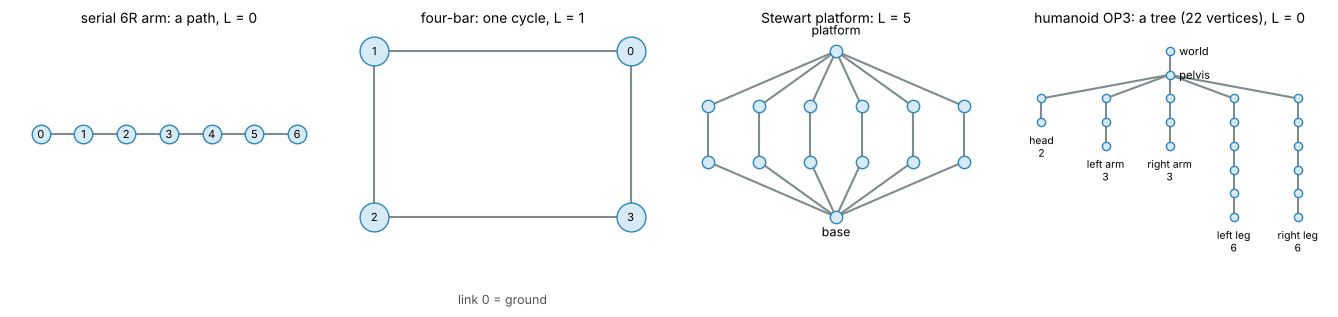

In [11]:
# Draw the four link-joint graphs: vertices = links, edges = joints.
def draw_graph(ax, pos, edges, title, colors=None, labels=None, ms=7):
    for k, (a, b) in enumerate(edges):
        ax.plot(*zip(pos[a], pos[b]), "-", color=(colors[k] if colors else "#7f8c8d"), lw=1.5, zorder=1)
    P = np.array(list(pos.values()))
    ax.scatter(P[:, 0], P[:, 1], s=ms ** 2 * 2.2, c="#d6eaf8", ec="#2e86c1", zorder=2)
    if labels:
        for i, t in labels.items(): ax.text(*pos[i], t, ha="center", va="center", fontsize=8, zorder=3)
    ax.set_title(title, fontsize=10); ax.set_axis_off(); ax.grid(False); ax.margins(0.12)

fig, axs = plt.subplots(1, 4, figsize=(13.5, 3.5))
draw_graph(axs[0], {i: (i, 0) for i in range(7)}, serial6, "serial 6R arm: a path, L = 0", labels={i: str(i) for i in range(7)}, ms=9)
ang = np.pi / 4 + np.arange(4) * np.pi / 2
draw_graph(axs[1], {i: (np.cos(a), np.sin(a)) for i, a in enumerate(ang)}, fourbar, "four-bar: one cycle, L = 1",
           labels={0: "0", 1: "1", 2: "2", 3: "3"}, ms=14)
axs[1].text(0, -1.45, "link 0 = ground", ha="center", fontsize=9, color="#555")
pos_s = {0: (0, 0), 1: (0, 3)}
for k in range(6):
    x = (k - 2.5) * 0.9
    pos_s[2 + 2 * k], pos_s[3 + 2 * k] = (x, 1.0), (x, 2.0)
draw_graph(axs[2], pos_s, stewart, "Stewart platform: L = 5", ms=6)
axs[2].text(0, -0.35, "base", ha="center", fontsize=9); axs[2].text(0, 3.3, "platform", ha="center", fontsize=9)
# OP3 tree by depth-first layout
depth, order = {}, []
def dfs(b, dpt):
    depth[b] = dpt
    kids = [i for i in range(mop3.nbody) if i != b and int(mop3.body_parentid[i]) == b and not (b == 0 and i == 0)]
    if not kids: order.append(b)
    for k in kids: dfs(k, dpt + 1)
dfs(0, 0)
xleaf = {b: i for i, b in enumerate(order)}
posop3 = {}
def place(b):
    kids = [i for i in range(1, mop3.nbody) if int(mop3.body_parentid[i]) == b]
    if not kids: posop3[b] = (xleaf[b], -depth[b]); return xleaf[b]
    xs_ = [place(k) for k in kids]; posop3[b] = (np.mean(xs_), -depth[b]); return posop3[b][0]
place(0)
draw_graph(axs[3], posop3, [(a, b) for a, b in op3_edges], "humanoid OP3: a tree (22 vertices), L = 0", ms=4)
for leaf, name in zip([3, 6, 9, 15, 21], ["head\n2", "left arm\n3", "right arm\n3", "left leg\n6", "right leg\n6"]):
    axs[3].text(posop3[leaf][0], posop3[leaf][1] - 0.5, name, ha="center", va="top", fontsize=7.5)
axs[3].text(posop3[0][0] + 0.15, 0.0, "world", fontsize=8, va="center"); axs[3].text(posop3[1][0] + 0.15, -1.0, "pelvis", fontsize=8, va="center")
plt.tight_layout(); plt.show()

Equation (1.2) counts loops; it does not by itself say how many **degrees of freedom** the mechanism has. That is the
job of Grübler's formula (Notebook 1.3), which combines $N$, $J$ and the freedoms $f_i$ of the individual joints.

Closed chains deserve one practical remark. A mechanism that is a tree in the model can become a closed chain in
operation: a humanoid standing on both feet closes a loop through the ground (pelvis – leg – floor – leg – pelvis), and
a robot that grips a workpiece fixed in the cell closes a loop through the workpiece. Simulators such as MuJoCo
therefore treat loop closure as *constraints*: they build a tree of joints and add an *equality constraint* for each
closing joint. We have already seen that device in Section 3 for the helical pair.

## 5. Naming and classifying manipulators

**Naming.** A manipulator is named by listing its joint types from the base to the tip: an **RRR** arm has three
revolute joints; an **RPR** arm has a revolute, a prismatic and a revolute joint; a **6R** arm has six revolute joints.
Capital letters denote the types of Section 3. The list also gives the **number of joints** $n$, which for a serial
chain of 1-freedom joints equals the number of degrees of freedom.

**Arm and wrist.** The first three joints mainly place the **wrist centre** in space; they form the **arm**
(*positioning structure*). The remaining joints orient the tool; they form the **wrist** (*orienting structure*).
A **spherical wrist** is three revolute joints whose axes meet at one point; it makes the position of that point
independent of the wrist angles, which greatly simplifies inverse kinematics (Chapter 4).

**Classical arm geometries.** Naming the arm by its first three joints gives the five classical configurations.
Their names describe the shape of the volume the wrist centre can reach (Section 1.5 will sample these volumes).

| Arm geometry | Joint sequence | Characteristic | Typical use |
|:--|:--|:--|:--|
| **Cartesian** (gantry) | PPP | the three axes are mutually perpendicular straight lines | 3-D printers, CNC machines, pick-and-place gantries |
| **Cylindrical** | RPP | one rotation about a vertical axis, then vertical and radial slides | older material handling robots |
| **Spherical** (polar) | RRP | two perpendicular rotations, then a radial slide | the Stanford arm; hydraulic cranes |
| **SCARA** | RRP, **axes parallel** | two parallel vertical revolute axes and a vertical slide: stiff vertically, compliant horizontally | electronics assembly, screw driving |
| **Articulated** (anthropomorphic) | RRR | a vertical axis, then two parallel horizontal axes (shoulder, elbow) | PUMA, KUKA, ABB, UR and nearly all general-purpose arms |

Notice that **joint types alone do not determine the geometry**: the SCARA and the spherical arm are both RRP.
What distinguishes them is the *relation between the joint axes* — parallel in the SCARA, perpendicular in the spherical
arm. Notebook 1.2 will measure such relations on real robots. The figure draws all five geometries in one typical
configuration (circles are revolute and squares prismatic joints, arrows are joint axes).

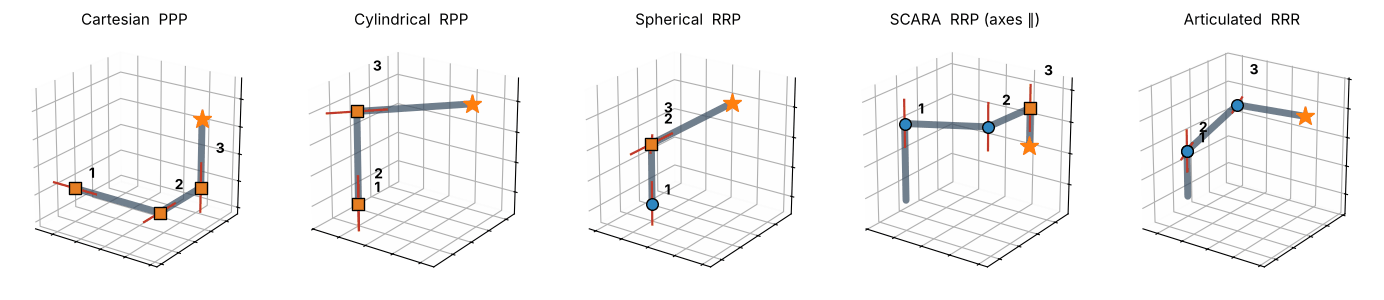

angle between joint axes 1 and 2:   spherical arm 90°,   SCARA 0°


In [12]:
# Each geometry: a function returning the polyline of the links and the joints as (position, axis, type).
def cartesian(q):
    x, y, z = q
    pts = np.array([[0, 0, 0], [x, 0, 0], [x, y, 0], [x, y, z]], float)
    return pts, [(pts[0], (1, 0, 0), "P"), (pts[1], (0, 1, 0), "P"), (pts[2], (0, 0, 1), "P")]

def cylindrical(q):
    th, z, r = q
    pts = np.array([[0, 0, 0], [0, 0, z], [r * np.cos(th), r * np.sin(th), z]], float)
    return pts, [(pts[0], (0, 0, 1), "R"), (pts[0], (0, 0, 1), "P"), (pts[1], (np.cos(th), np.sin(th), 0), "P")]

def spherical(q):
    th, ph, r = q; h = 0.5
    d = np.array([np.cos(ph) * np.cos(th), np.cos(ph) * np.sin(th), np.sin(ph)])
    pts = np.array([[0, 0, 0], [0, 0, h], [0, 0, h] + r * d])
    return pts, [(pts[0], (0, 0, 1), "R"), (pts[1], (-np.sin(th), np.cos(th), 0), "R"), (pts[1], d, "P")]

def scara(q):
    t1, t2, z = q; L1, L2 = 0.6, 0.5
    p1 = np.array([L1 * np.cos(t1), L1 * np.sin(t1), 0.6]); p2 = p1 + [L2 * np.cos(t1 + t2), L2 * np.sin(t1 + t2), 0]
    pts = np.array([[0, 0, 0], [0, 0, 0.6], p1, p2, p2 - [0, 0, z]])
    return pts, [(pts[1], (0, 0, 1), "R"), (p1, (0, 0, 1), "R"), (p2, (0, 0, 1), "P")]

def articulated(q):
    t1, t2, t3 = q; L1, L2, h = 0.6, 0.55, 0.4
    u = np.array([np.cos(t1), np.sin(t1), 0]); k = np.array([0, 0, 1.0])
    p1 = np.array([0, 0, h]); p2 = p1 + L1 * (np.cos(t2) * u + np.sin(t2) * k)
    p3 = p2 + L2 * (np.cos(t2 + t3) * u + np.sin(t2 + t3) * k)
    pts = np.array([[0, 0, 0], p1, p2, p3])
    n2 = np.array([-np.sin(t1), np.cos(t1), 0])
    return pts, [(p1, (0, 0, 1), "R"), (p1, n2, "R"), (p2, n2, "R")]

geoms = [("Cartesian  PPP", cartesian, (0.7, 0.5, 0.5)), ("Cylindrical  RPP", cylindrical, (0.8, 0.6, 0.7)),
         ("Spherical  RRP", spherical, (0.6, 0.5, 0.7)), ("SCARA  RRP (axes ∥)", scara, (0.5, 1.0, 0.3)),
         ("Articulated  RRR", articulated, (0.4, 0.8, -0.9))]
fig = plt.figure(figsize=(14, 3.9))
for k, (title, fn, q) in enumerate(geoms):
    ax = fig.add_subplot(1, 5, k + 1, projection="3d")
    pts, joints = fn(q)
    ax.plot(*pts.T, "-", color="#34495e", lw=5, solid_capstyle="round", alpha=0.7)
    for n_, (p, a, typ) in enumerate(joints, 1):
        a = np.asarray(a, float) / np.linalg.norm(a)
        ax.plot(*np.array([p - 0.18 * a, p + 0.18 * a]).T, "-", color="#c0392b", lw=1.6)
        ax.scatter(*p, marker="o" if typ == "R" else "s", s=70, c="#2e86c1" if typ == "R" else "#e67e22", zorder=5, edgecolors="k")
        ax.text(*(p + [0.07, 0.07, 0.07 + 0.09 * (n_ - 1)]), str(n_), fontsize=10, weight="bold")
    ax.plot(*pts[-1], "*", color="#ff7f0e", ms=14)
    lo_, hi_ = np.minimum(pts.min(0), 0) - 0.15, pts.max(0) + 0.15
    c_, r_ = (lo_ + hi_) / 2, (hi_ - lo_).max() / 2
    new_axes3d(ax, lim=tuple((c_[i] - r_, c_[i] + r_) for i in range(3)), title=title, elev=22, azim=-55, ticks=False)
    ax.set_xlabel(""); ax.set_ylabel(""); ax.set_zlabel("")
plt.tight_layout(); plt.show()

# The distinction between SCARA and the spherical arm is the angle between the first two axes:
_, js = spherical((0.6, 0.5, 0.7)); _, jc_ = scara((0.5, 1.0, 0.3))
ang = lambda a, b: np.degrees(np.arccos(abs(np.dot(a, b) / np.linalg.norm(a) / np.linalg.norm(b))))
print(f"angle between joint axes 1 and 2:   spherical arm {ang(js[0][1], js[1][1]):.0f}°,   SCARA {ang(jc_[0][1], jc_[1][1]):.0f}°")

## 6. Worked examples

**Example 1.1.1 (naming).** A robot has, from base to tip, a revolute joint about a vertical axis, a revolute joint
about a horizontal axis, a prismatic joint along the second link, and three revolute joints whose axes meet at a
point. Name the robot, identify the arm and wrist, and classify the arm.

*Solution.* The joint sequence is **RRPRRR**; $n = 6$ joints of one freedom each, so the robot has 6 DOF. The first three
joints (RRP) form the arm; the last three, with concurrent axes, form a **spherical wrist**. In the arm the
first two axes are perpendicular (vertical, then horizontal) and the third is a radial slide, so this is a
**spherical (polar) arm** — the structure of the Stanford arm — and not a SCARA, for which the first two axes would be
parallel.

**Example 1.1.2 (independent loops).** How many independent loops does (a) the Stewart platform and (b) a humanoid
standing on both feet have?

*Solution.* (a) The platform has $N = 2 + 12 = 14$ links (base, platform, and two parts for each of the 6 legs) and
$J = 6 \times 3 = 18$ joints (universal, prismatic, spherical on each leg), so $L = 18 - 14 + 1 = 5$.
(b) The OP3 model consists of the ground and 21 links. MuJoCo attaches the pelvis to the world by a *free joint*, but this is a
bookkeeping device (it places the floating base), not a mechanical connection. Mechanically the robot is a tree of
$N = 22$ vertices (ground included, though unattached) and $J = 20$ real joints. Standing on both feet adds two
foot–floor contacts as joints: $J = 22$, $N = 22$, so $L = 22 - 22 + 1 = 1$. The single loop runs pelvis – leg – floor – other leg – pelvis.

**Example 1.1.3 (constraints of a pair).** How many of the six relative freedoms does a cylindrical joint remove? What
does it become if the rotation is locked?

*Solution.* $f = 2$ (one rotation, one translation along the same axis), so $c = 6 - 2 = 4$. With the rotation locked
only the translation along the axis remains: a **prismatic** joint, $f = 1$, $c = 5$.

**Example 1.1.4 (where is the hand?).** The Dynamixel 2R has $L_1 = L_2 = 0.18$ m. Find the hand position for
$\theta_1 = -45^\circ$, $\theta_2 = 90^\circ$, and compare with MuJoCo.

*Solution.* $X = 0.18\cos(-45^\circ) + 0.18\cos(45^\circ) = 0.18\sqrt2 = 0.2546$ m and
$Y = 0.18\sin(-45^\circ) + 0.18\sin(45^\circ) = 0$. The hand lies on the $X$ axis, 0.2546 m from the shoulder, which is less than
the full reach $L_1 + L_2 = 0.36$ m.

**Example 1.1.5 (a rigid body needs one frame).** A point on the UR5e forearm is fixed in the forearm frame at
$\,{}^{F}P = (0,\ 0.05,\ 0.10)$ m. Show that its world position follows from the forearm frame's pose
$({}^{W}_{F}R,\ {}^{W}P_{FORG})$ alone, by ${}^{W}P = {}^{W}_{F}R\,{}^{F}P + {}^{W}P_{FORG}$ — the *mapping* of Chapter 2 — and that the point's
distance from the forearm origin never changes.

*Solution.* Because the point is fixed in the rigid link, ${}^{F}P$ is constant while only the pose of $\{F\}$ changes with the joints,
so the mapping gives the world position; and $\lVert {}^{W}P - {}^{W}P_{FORG}\rVert = \lVert {}^{W}_{F}R\,{}^{F}P\rVert = \lVert{}^{F}P\rVert = 0.1118$ m because rotations preserve length.

**Example 1.1.6 (reachable region of a SCARA).** A SCARA arm has horizontal links of $0.6$ m and $0.5$ m and a vertical stroke of
$0.3$ m. Ignoring joint limits, find the inner and outer radii of the region the tool can reach in a horizontal plane and the volume of
the reachable region.

*Solution.* The tool is at distance between $|L_1 - L_2| = 0.1$ m and $L_1 + L_2 = 1.1$ m from the base axis, so the horizontal
region is an annulus. The reachable volume is the annulus times the stroke, $\pi\,(1.1^2 - 0.1^2)(0.3) = 1.131$ m³. (Notebook 1.5 proves
the annulus statement.)

In [13]:
# Example 1.1.1: names
seq = "RRPRRR"; print("1.1.1  name:", seq, "| n =", len(seq), "| arm:", seq[:3], "| wrist:", seq[3:])

# Example 1.1.2: loops
edges_phys = [e for e in op3_edges if e != (1, 0)] + [(15, 0), (21, 0)]       # drop the virtual free joint, add two foot contacts
print("1.1.2  Stewart:", loops(14, stewart), "| OP3 standing on both feet:", loops(mop3.nbody, edges_phys),
      f"(N = {mop3.nbody}, J = {len(edges_phys)})")
assert loops(14, stewart) == 5 and loops(mop3.nbody, edges_phys) == 1

# Example 1.1.3: constraints
f_cyl = mech.LOWER_PAIRS["cylindrical"][1]; print("1.1.3  cylindrical: f =", f_cyl, ", c =", 6 - f_cyl, "; with rotation locked -> P: f =", mech.LOWER_PAIRS["prismatic"][1])

# Example 1.1.4: the 2R hand position
q = np.radians([-45, 90]); p = fk_2r(q)
print("1.1.4  hand:", p.round(4), " 0.18*sqrt(2) =", round(0.18 * np.sqrt(2), 4), " MuJoCo:", hand_from_mujoco(q).round(4))
assert np.allclose(p, [0.18 * np.sqrt(2), 0], atol=1e-12) and np.allclose(p, hand_from_mujoco(q))

# Example 1.1.5: rigid body, one frame
bidf = mujoco.mj_name2id(mu, mujoco.mjtObj.mjOBJ_BODY, "forearm_link")
P_F = np.array([0, 0.05, 0.10]); radii = []
for _ in range(50):
    du.qpos[:] = [rng.uniform(lo, hi) for lo, hi in mu.jnt_range]; mujoco.mj_forward(mu, du)
    P_W = du.xmat[bidf].reshape(3, 3) @ P_F + du.xpos[bidf]
    radii.append(np.linalg.norm(P_W - du.xpos[bidf]))
print("1.1.5  |P| =", np.linalg.norm(P_F).round(4), " distance from the forearm origin over 50 poses:", round(min(radii), 6), "…", round(max(radii), 6))
assert np.ptp(radii) < 1e-12 and abs(np.linalg.norm(P_F) - 0.1118) < 1e-4

# Example 1.1.6: SCARA reachable region
print("1.1.6  annulus radii:", round(abs(0.6 - 0.5), 3), "to", round(0.6 + 0.5, 3), " volume =", round(np.pi * (1.1 ** 2 - 0.1 ** 2) * 0.3, 4), "m^3")
assert abs(np.pi * (1.1 ** 2 - 0.1 ** 2) * 0.3 - 1.131) < 1e-3

1.1.1  name: RRPRRR | n = 6 | arm: RRP | wrist: RRR
1.1.2  Stewart: 5 | OP3 standing on both feet: 1 (N = 22, J = 22)
1.1.3  cylindrical: f = 2 , c = 4 ; with rotation locked -> P: f = 1
1.1.4  hand: [0.2546 0.    ]  0.18*sqrt(2) = 0.2546  MuJoCo: [0.2546 0.    ]
1.1.5  |P| = 0.1118  distance from the forearm origin over 50 poses: 0.111803 … 0.111803
1.1.6  annulus radii: 0.1 to 1.1  volume = 1.131 m^3


## 7. Summary

| Idea | Result |
|:--|:--|
| Robot manipulator | links (rigid bodies) joined by joints; base = link 0, end-effector on the last link; actuators move joints, sensors measure them |
| Rigid body | pairwise distances constant ⇒ **one frame** describes the whole link |
| Lower pairs | R, P, H ($f=1$), C ($f=2$), S, E ($f=3$); each removes $c=6-f$ of 6 relative freedoms; contact over a *surface* |
| Higher pairs | contact along a line or at a point (gears, cams); not used for ordinary robot joints |
| Chains | serial (path), tree (no loop), closed (loops); $L = J - N + 1$ independent loops |
| Naming | joint letters from base to tip (RRR, RPR, 6R, SCARA = RRPR); first three joints = *arm*, rest = *wrist* |
| Geometries | Cartesian PPP, cylindrical RPP, spherical RRP, SCARA RRP with parallel axes, articulated RRR |
| Why mathematics | six questions — FK, IK, Jacobian, statics, dynamics, trajectory/control — all start from the joint variables |

### Common mistakes

* Counting the **ground** as a link in $N$ for Grübler's formula and loop counts but forgetting it when numbering links
  — link 0 is always the fixed base.
* Assuming the joint **sequence** alone fixes the geometry: a SCARA and a spherical arm are both RRP; the *axis
  relations* decide.
* Treating the universal (Hooke) joint as a lower pair: it is a *composite* of two revolute pairs.
* Believing a mechanism with $n$ joints has $n$ degrees of freedom: that holds for *serial* chains of 1-freedom joints
  only; loops reduce the freedom (Notebook 1.3).
* Forgetting that MuJoCo's zero configuration need not be the textbook's: the Dynamixel 2R hangs down at $q = 0$.

## Exercises

**1.1.1** Name the kind of joint (and give $f$ and $c=6-f$) for: (a) a door hinge, (b) a drawer, (c) a jar lid on its
thread, (d) a shaft that rotates in and slides along a bearing, (e) a hip joint, (f) a computer mouse on a desk.

<details><summary>Answer</summary>

(a) revolute R, $f=1$, $c=5$; (b) prismatic P, $f=1$, $c=5$; (c) helical H, $f=1$, $c=5$; (d) cylindrical C, $f=2$,
$c=4$; (e) spherical S, $f=3$, $c=3$; (f) planar E, $f=3$, $c=3$ (two translations and a rotation about the normal;
the mouse is also a *higher* pair if it rolls, but a lower pair if it slides on its flat base).
</details>

**1.1.2** Compute the number of independent loops of (a) a planar six-bar (Watt) linkage with 6 links and 7 joints,
(b) a serial arm with a two-finger gripper (the fingers are two extra links attached to the last link), (c) the
slider-crank (4 links, 4 joints).

<details><summary>Answer</summary>

(a) $L = 7 - 6 + 1 = 2$; (b) the gripper adds 2 links and 2 joints, so $J - N$ is unchanged: a tree, $L = 0$; (c) $L = 4 - 4 + 1 = 1$.
</details>

**1.1.3** The SCARA and the spherical arm are both RRP. Explain what distinguishes them and give one consequence for
the shape of the reachable space.

<details><summary>Answer</summary>

The angle between the first two revolute axes: $0^\circ$ (parallel, vertical) for the SCARA and $90^\circ$ for the
spherical arm (the code of Section 5 prints these angles). A SCARA's tool moves in a *horizontal* plane with a vertical
stroke, hence its envelope is a (annular) cylinder; the spherical arm sweeps a spherical shell.
</details>

**1.1.4** Show that a spherical joint can be built from three revolute joints whose axes meet in a point, by checking in
MuJoCo that the common point does not move while the three angles are changed at random.

<details><summary>Answer</summary>

Build three hinge joints at the origin with axes $\hat Z$, $\hat Y$, $\hat X$ in nested bodies. The origin of the last
body stays at the origin for every set of angles (the check below prints a deviation of $0$); the three angles give
three orientation freedoms, $f=3$, as for a spherical joint.
</details>

**1.1.5** (*MuJoCo*) Using only MuJoCo's forward kinematics of the Dynamixel 2R, find the largest distance of the hand
from the shoulder over 2000 random joint configurations within the limits, and compare it with $L_1+L_2$.

<details><summary>Answer</summary>

The maximum is just below $L_1+L_2 = 0.36$ m (it is attained exactly at $\theta_2=0$, a measure-zero set, so random sampling
approaches but does not reach it; the check below prints the value).
</details>

**1.1.6** Is a garden hose a rigid body? Which assumption of kinematics fails, and what would you need to model it?

<details><summary>Answer</summary>

No: the distances between points of the hose change when it bends, so its configuration cannot be described by a single
frame. Kinematics of such *continuum* or *flexible* bodies needs many coordinates (for example a chain of short rigid
segments, or a curve with shape parameters).
</details>

In [14]:
# --- verification of the exercise answers ---
# 1.1.2
tree_gripper = [(i, i + 1) for i in range(6)] + [(6, 7), (6, 8)]             # arm + two fingers: 9 links, 8 joints
print("1.1.2  (a) Watt six-bar:", 7 - 6 + 1, "| (b) arm + gripper:", loops(9, tree_gripper), "| (c) slider-crank:", loops(4, fourbar))
assert 7 - 6 + 1 == 2 and loops(9, tree_gripper) == 0 and loops(4, fourbar) == 1

# 1.1.3: angles between axes
print("1.1.3 axis angles: spherical", round(ang(js[0][1], js[1][1])), "°, SCARA", round(ang(jc_[0][1], jc_[1][1])), "°")
assert round(ang(js[0][1], js[1][1])) == 90 and round(ang(jc_[0][1], jc_[1][1])) == 0

# 1.1.4: spherical joint = three concurrent hinges
I = '<inertial pos="0 0 0" mass="0.1" diaginertia="1e-3 1e-3 1e-3"/>'
xml3 = f"""<mujoco><worldbody><body>{I}<joint name="a" axis="0 0 1"/><body>{I}<joint name="b" axis="0 1 0"/><body>{I}<joint name="c" axis="1 0 0"/>
          <geom size="0.01"/><site name="tip" pos="0 0 0"/></body></body></body></worldbody></mujoco>"""
m3, d3 = mju.load(xml3)
dev = 0.0
for _ in range(100):
    d3.qpos[:] = rng.uniform(-np.pi, np.pi, 3); mujoco.mj_forward(m3, d3)
    dev = max(dev, np.linalg.norm(d3.site("tip").xpos))
print("1.1.4 deviation of the common point:", dev, "| nv =", m3.nv); assert dev < 1e-15 and m3.nv == 3

# 1.1.5: reach
Q = rng.uniform(m2.jnt_range[:, 0], m2.jnt_range[:, 1], size=(2000, 2))
reach = max(np.linalg.norm(hand_from_mujoco(q)) for q in Q)
print(f"1.1.5 largest distance over 2000 samples: {reach:.5f} m  (L1 + L2 = {L1 + L2:.4f} m)"); assert reach <= L1 + L2 + 1e-12 and reach > 0.35

1.1.2  (a) Watt six-bar: 2 | (b) arm + gripper: 0 | (c) slider-crank: 1
1.1.3 axis angles: spherical 90 °, SCARA 0 °
1.1.4 deviation of the common point: 0.0 | nv = 3
1.1.5 largest distance over 2000 samples: 0.36000 m  (L1 + L2 = 0.3600 m)


## Further reading and lectures

* Craig, Ch. 1 (the scope of the subject and the notation of the rest of the book); Lynch & Park, Ch. 2 (degrees of freedom, joint types);
  Spong et al., Ch. 1 (components, joints, workspace and the classical arm geometries); Siciliano et al., Ch. 1 (classification of manipulators).
* Video: [Prof. G. C. Nandi — Lecture 1 — Introduction](https://www.youtube.com/watch?v=7_EEBOgdGM8); [Prof. G. C. Nandi — Lecture 2 — A simple two-link manipulator](https://www.youtube.com/watch?v=4eAlCjFMq2Q); [Modern Robotics — 2.2 DOF of a robot (Grübler)](https://www.youtube.com/watch?v=zI64DyaRUvQ).
* MuJoCo documentation on [joints](https://mujoco.readthedocs.io/en/stable/XMLreference.html#body-joint) and
  [equality constraints](https://mujoco.readthedocs.io/en/stable/XMLreference.html#equality).
* Next: Notebook 1.2 takes the vocabulary of this notebook to six real robot models and measures their joints.

---

[Chapter contents](README.md) &nbsp;·&nbsp; [1.2 A Tour of Real Robots →](1.2-a-tour-of-real-robots.ipynb)